In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import json
import re

from pathlib import Path
from matplotlib.lines import Line2D

In [3]:
from src.laptop import Laptop
results_path = Path("./results")

In [ ]:
## Load all CSV files into a dictionary of DataFrames
# dfs = {}

# for noise in [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5]:
#     # Convert 0.05 to 5, format as '05', and prefix with 'df'
#     key = f"{int(noise * 100):02d}"
#     dfs[key] = pd.read_csv(f"{results_path}/triage_experiment_n1000_noise{noise}.csv")

# df= dfs['25']  # Access the DataFrame for noise level 0.25
# # df.head()

In [71]:
# alternatively, load single dataframe for noise level 0.25
df = pd.read_csv(f"{results_path}/triage_experiment_n1000_noise0.25.csv")
# df.head()

In [ ]:
# ### Save this code block to check for NaN values in the DataFrame:

# # To see the count of NaN values in each individual column:
# nan_counts_per_column = df.isna().sum()
# print(nan_counts_per_column)

# # To get the absolute total of all NaN values across the entire DataFrame:
# total_nans = df.isna().sum().sum()
# print(total_nans)

# # run if you want to drop rows with NaN values in specific columns, for example, "econ_reward" and "eco_reward":
# df = df.dropna(subset=["econ_reward", "eco_reward"])

In [72]:
def get_ce_route(policy_str):
    try:
        path = json.loads(policy_str)
        last_step = path[-1]
        action = last_step[1]
        if action.startswith("CE:"):
            return action.split(": ")[-1].split("_")[0]
    except (json.JSONDecodeError, IndexError):
        return "Unknown"


df["ce_route"] = df["readable_policy"].apply(get_ce_route)
df.ce_route.unique()

<StringArray>
['Reuse', 'Recycle', 'Refurbish', 'Repair']
Length: 4, dtype: str

In [73]:
df["component_name"] = df["component_name"].str.capitalize()
df.component_name.unique()

<StringArray>
['Laptop', 'Motherboard', 'Display', 'Keyboard', 'Battery', 'Chassis']
Length: 6, dtype: str

['Laptop', 'Motherboard', 'Display', 'Keyboard', 'Battery', 'Chassis']

In [101]:
# --- Global Plotting Settings ---

sns.set_theme(style="ticks", palette="colorblind", context="paper")
title_fontsize = 18
label_fontsize = 15
tick_fontsize = 13
legend_fontsize = 11
panel_fontsize = 20
line_width = 3
marker_size = 6
scatter_size = 45


#assign specific pallete colours from the general colorblind palette to each pathway for consistency across plots
_palette = sns.color_palette("colorblind").as_hex()
ce_palette = {
    "Reuse":     _palette[0],  # blue        #0173b2
    "Refurbish": _palette[1],  # orange      #de8f05
    "Repair":    _palette[2],  # bluish green #029e73
    "Recycle":   _palette[3],  # vermillion  #d55e00
    "Unknown":   _palette[7],  # grey        #949494
}


# Define specific markers for each component type for clarity
component_markers = {
    "laptop": "o",  # Circle for the full laptop
    "Motherboard": "^",  # Triangle up for Motherboard
    "Display": "s",  # Square for Display
    "Battery": "P",  # Plus (filled) for Battery
    "Chassis": "D",  # Diamond for Chassis
    "Keyboard": "8",  # Octagram for Keyboard
    # Add other components as needed
}

In [75]:
# --- Prepare Data for Plotting ---

# Define a logical order for the CE routes to make the plot easier to interpret
ce_order = ["Reuse", "Refurbish", "Repair", "Recycle"]
df["ce_route"] = pd.Categorical(df["ce_route"], categories=ce_order, ordered=True)

# Separate whole-laptop decisions from disassembled component decisions
df_laptop = df[df['component_name'] == 'laptop']
df_components = df[df['component_name'] != 'laptop']

#dummy laptop is for generating the theoretical maximum envelope (the black line)
dummy_laptop = Laptop(value=1200) 
ce_options = dummy_laptop.ce_options

In [78]:
df["ce_route"]

0           Reuse
1           Reuse
2         Recycle
3       Refurbish
4          Repair
          ...    
2351      Recycle
2352       Repair
2353      Recycle
2354        Reuse
2355    Refurbish
Name: ce_route, Length: 2356, dtype: category
Categories (4, str): ['Reuse' < 'Refurbish' < 'Repair' < 'Recycle']

In [9]:
_noise_files = []
for _csv_path in results_path.glob("triage_experiment_n1000_noise*.csv"):
    _match = re.search(r"_noise([0-9]+(?:\.[0-9]+)?)\.csv$", _csv_path.name)
    if _match:
        _noise_files.append((float(_match.group(1)), _csv_path))
        
_noise_files.sort(key=lambda item: item[0])

_noise_frames = []
_noise_summaries = []
for _noise_value, _csv_path in _noise_files:
    _frame = pd.read_csv(_csv_path)
    _required_noise_columns = {"episode_id", "profit", "true_health", "observed_health"}
    _missing_noise_columns = _required_noise_columns.difference(_frame.columns)
    if _missing_noise_columns:
        raise ValueError(
            f"{_csv_path.name} is missing required columns: "
            f"{sorted(_missing_noise_columns)}"
        )

    _frame["_noise_level"] = _noise_value
    _noise_frames.append(_frame)
    _episode_profit = (
        _frame.groupby("episode_id", as_index=False)["profit"]
        .sum()
        .rename(columns={"profit": "episode_profit"})
    )
    _profits = pd.to_numeric(_episode_profit["episode_profit"], errors="coerce").dropna()
    _noise_summaries.append(
        {
            "noise_level": _noise_value,
            "mean_profit": _profits.mean(),
            "median_profit": _profits.median(),
            "std_profit": _profits.std(),
            "variance_profit": _profits.var(),
            "iqr_profit": _profits.quantile(0.75) - _profits.quantile(0.25),
            "episode_profits": _episode_profit.assign(noise_level=_noise_value),
        }
    )

_noise_data = pd.concat(_noise_frames, ignore_index=True)
_noise_summary = pd.DataFrame(
    [{key: value for key, value in row.items() if key != "episode_profits"}
     for row in _noise_summaries]
)
_episode_profit_data = pd.concat(
    [row["episode_profits"] for row in _noise_summaries], ignore_index=True
)
_episode_profit_data["_noise_label"] = _episode_profit_data["noise_level"].map(
    lambda value: f"{value:.2f}"
)
_noise_order = [f"{value:.2f}" for value, _ in _noise_files]

_required_environment_columns = {"_noise_level", "episode_id", "eco_reward"}
_missing_environment_columns = _required_environment_columns.difference(_noise_data.columns)
if _missing_environment_columns:
    raise ValueError(
        "Noise data is missing columns required for environmental scores: "
        f"{sorted(_missing_environment_columns)}"
    )

_environment_rows = _noise_data.loc[
    :, ["_noise_level", "episode_id", "eco_reward"]
].copy()
_environment_rows["eco_reward"] = pd.to_numeric(
    _environment_rows["eco_reward"], errors="raise"
)
if _environment_rows[["_noise_level", "episode_id", "eco_reward"]].isna().any().any():
    raise ValueError("Noise data contains missing episode IDs, noise levels or environmental scores.")

# Environmental scores are per decision; average component scores within each episode.
_episode_environment_data = (
    _environment_rows.groupby(["_noise_level", "episode_id"], as_index=False)
    .agg(episode_environment=("eco_reward", "mean"))
    .rename(columns={"_noise_level": "noise_level"})
)
_episode_environment_data["_noise_label"] = _episode_environment_data["noise_level"].map(
    lambda value: f"{value:.2f}"
)
_environment_summary = (
    _episode_environment_data.groupby("noise_level")["episode_environment"]
    .agg(["mean", "median", "std"])
    .reset_index()
)

_noise_colors = sns.color_palette("colorblind")


In [ ]:


fuzzy_df = df.copy()

for column in ["true_health", "observed_health", "membership"]:
    fuzzy_df[column] = pd.to_numeric(fuzzy_df[column], errors="coerce")
fuzzy_df = fuzzy_df.dropna(
    subset=["true_health", "observed_health", "membership"]
).copy()

fuzzy_df["health_error"] = fuzzy_df["observed_health"] - fuzzy_df["true_health"]
fuzzy_df["_bias_class"] = np.select(
    [fuzzy_df["health_error"] > 0.01, fuzzy_df["health_error"] < -0.01],
    ["Over-estimated", "Under-estimated"],
    default="Near agreement",
)
_bias_order = ["Over-estimated", "Near agreement", "Under-estimated"]
fuzzy_df["_true_bin"] = pd.cut(
    fuzzy_df["true_health"], bins=np.linspace(0, 1, 11), include_lowest=True
)

if "dummy_laptop" not in globals():
    raise NameError("Run the preceding cell that defines dummy_laptop and its CE options.")
_fuzzy_options = dummy_laptop.ce_options
if not _fuzzy_options:
    raise ValueError("dummy_laptop has no CE options to plot.")

health_grid = np.linspace(0.0, 1.0, 500)
alpha_scale = float(dummy_laptop.value)
set_curves = {}
for option in _fuzzy_options:
    set_curves[option.name] = (
        np.asarray(
            [
                option.get_fuzzy_membership(health) * option.base_value
                / alpha_scale
                # _option.get_expected_reward(health)
                for health in health_grid
            ],
            dtype=float,
        )
    )

# _set_curves["Repair_Laptop"][250:] = 0.5 #remove upper tail of repair as it doesnt effect yeild directly only thorugh full traige score
envelope = np.max(np.vstack(list(set_curves.values())), axis=0)

_laptop_df = fuzzy_df[
    fuzzy_df["component_name"].astype(str).str.casefold() == "laptop"
].copy()

for _column in ["base_value", "alpha_value"]:
    _laptop_df[_column] = pd.to_numeric(_laptop_df[_column], errors="raise")

_laptop_df["fuzzy_yield"] = (
    _laptop_df["membership"] * _laptop_df["base_value"] / _laptop_df["alpha_value"]
)
_laptop_df["_route_method"] = _laptop_df["ce_route"].astype(str).str.split("_").str[0]






0           Reuse
1           Reuse
2         Recycle
18         Repair
19          Reuse
          ...    
2346        Reuse
2347    Refurbish
2348      Recycle
2354        Reuse
2355    Refurbish
Name: ce_route, Length: 661, dtype: category
Categories (4, str): ['Reuse' < 'Refurbish' < 'Repair' < 'Recycle']

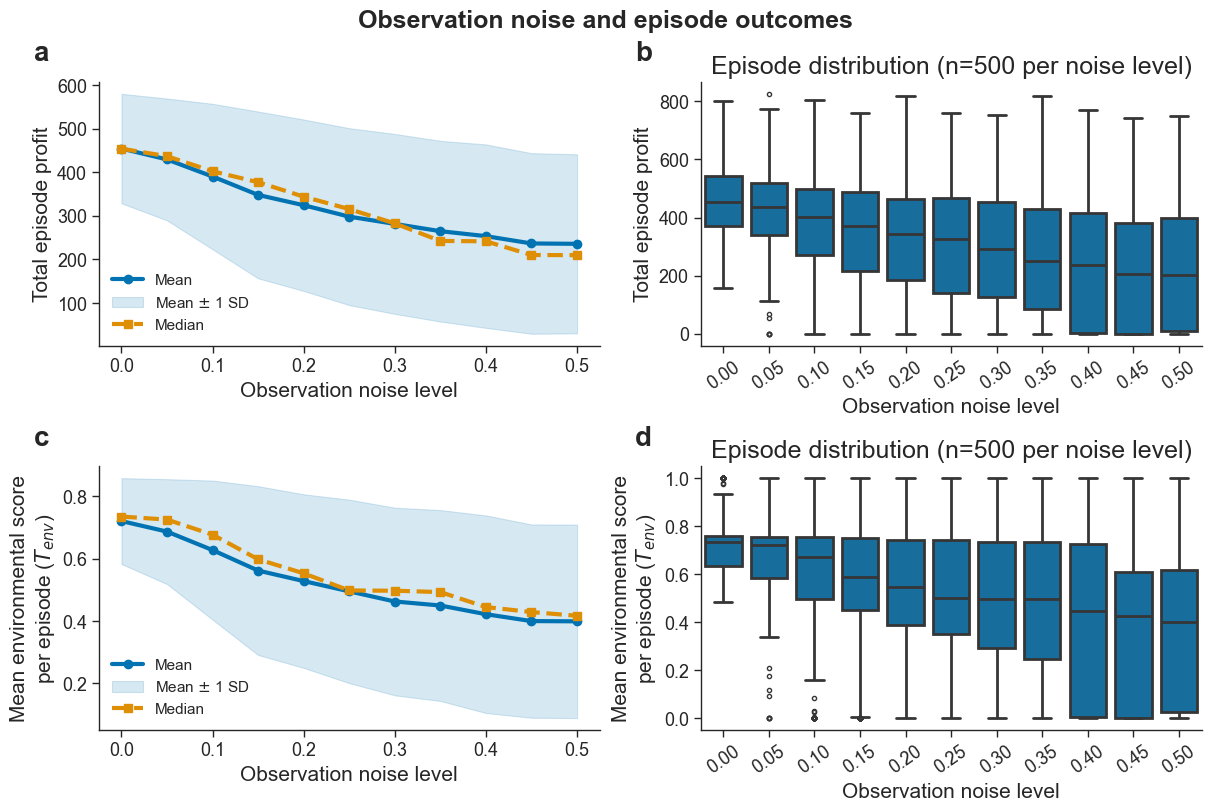

In [102]:


fig_noise = plt.figure(figsize=(12, 8.0), constrained_layout=True)
gs_noise = fig_noise.add_gridspec(2, 2)

for _row, _summary, _values, _value_column, _mean_column, _median_column, _std_column, _ylabel in [
    (
        0, _noise_summary, _episode_profit_data, "episode_profit",
        "mean_profit", "median_profit", "std_profit", "Total episode profit",
    ),
    (
        1, _environment_summary, _episode_environment_data, "episode_environment",
        "mean", "median", "std", "Mean environmental score\n" + r"per episode ($T_{env}$)",
    ),
]:
    ax = fig_noise.add_subplot(gs_noise[_row, 0])
    _x = _summary["noise_level"].to_numpy()
    _mean = _summary[_mean_column].to_numpy()
    _std = _summary[_std_column].to_numpy()
    ax.plot(_x, _mean, color=_noise_colors[0], marker="o",
            linewidth=line_width, markersize=marker_size, label="Mean")
    ax.fill_between(
        _x, _mean - _std, _mean + _std,
        color=_noise_colors[0], alpha=0.16, label=r"Mean $\pm$ 1 SD",
    )
    ax.plot(
        _x, _summary[_median_column], color=_noise_colors[1],
        marker="s", linestyle="--", linewidth=line_width,
        markersize=marker_size, label="Median",
    )
    ax.set(xlabel="Observation noise level", ylabel=_ylabel)
    ax.set_xlabel("Observation noise level", fontsize=label_fontsize)
    ax.set_ylabel(_ylabel, fontsize=label_fontsize)
    ax.tick_params(labelsize=tick_fontsize)
    ax.legend(frameon=False, fontsize=legend_fontsize)
    ax.text(
        -0.13, 1.08, "ac"[_row], transform=ax.transAxes,
        fontweight="bold", fontsize=panel_fontsize,
    )

    ax = fig_noise.add_subplot(gs_noise[_row, 1])
    _sample_size = min(500, _values.groupby("_noise_label").size().min())
    _box_sample = _values.groupby("_noise_label", group_keys=False).sample(
        n=_sample_size, random_state=7
    )
    sns.boxplot(
        data=_box_sample, x="_noise_label", y=_value_column, order=_noise_order,
        color=_noise_colors[0], fliersize=3, linewidth=line_width / 1.5, ax=ax,
    )
    ax.set(
        xlabel="Observation noise level", ylabel=_ylabel,
        title=f"Episode distribution (n={_sample_size} per noise level)",
    )
    ax.set_xlabel("Observation noise level", fontsize=label_fontsize)
    ax.set_ylabel(_ylabel, fontsize=label_fontsize)
    ax.set_title(f"Episode distribution (n={_sample_size} per noise level)", fontsize=title_fontsize)
    ax.tick_params(axis="both", labelsize=tick_fontsize)
    ax.tick_params(axis="x", rotation=35)
    ax.text(
        -0.13, 1.08, "bd"[_row], transform=ax.transAxes,
        fontweight="bold", fontsize=panel_fontsize,
    )

fig_noise.suptitle("Observation noise and episode outcomes", fontweight="bold", fontsize=title_fontsize)
sns.despine(fig=fig_noise)
Path("plots").mkdir(parents=True, exist_ok=True)
fig_noise.savefig("plots/noise_analysis.pdf", bbox_inches="tight")
fig_noise.savefig("plots/noise_analysis.png", dpi=300, bbox_inches="tight")
plt.show()


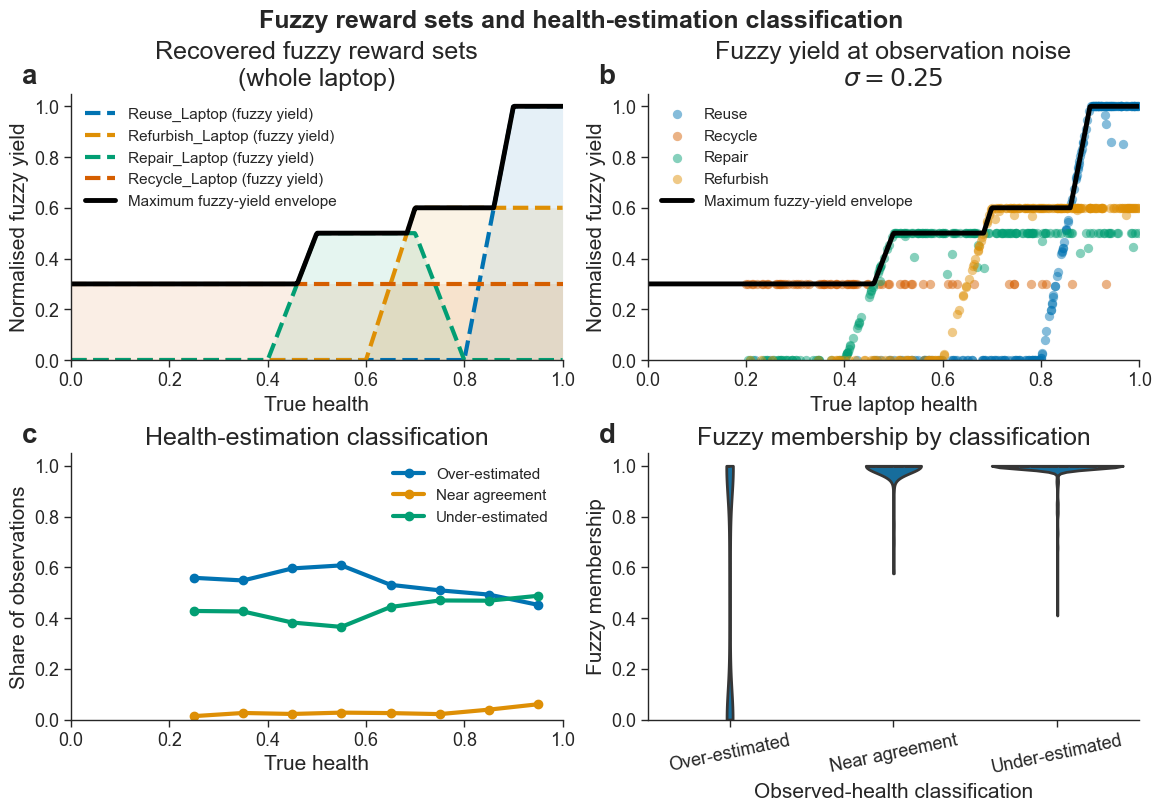

In [103]:

fig_fuzzy = plt.figure(figsize=(11.5, 8.0), constrained_layout=True)
gs_fuzzy = fig_fuzzy.add_gridspec(2, 2)

# a) Recovered fuzzy reward sets and their upper envelope.
ax = fig_fuzzy.add_subplot(gs_fuzzy[0, 0])
for option_name, _curve in set_curves.items():
    pathway = option_name.split("_", maxsplit=1)[0]
    ax.plot(
        health_grid,
        _curve,
        color=ce_palette[pathway],
        linestyle="--",
        linewidth=line_width,
        label=f"{option_name} (fuzzy yield)",
    )
    ax.fill_between(health_grid, 0, _curve, color=ce_palette[pathway], alpha=0.10, linewidth=0)
ax.plot(
    health_grid,
    envelope,
    color="black",
    linewidth=line_width + 0.5,
    label="Maximum fuzzy-yield envelope",
)
ax.set(
    title="Recovered fuzzy reward sets\n(whole laptop)",
    xlabel="True health",
    ylabel="Normalised fuzzy yield",
    xlim=(0, 1),
    ylim=(0, 1.05),
)
ax.set_title("Recovered fuzzy reward sets\n(whole laptop)", fontsize=title_fontsize)
ax.set_xlabel("True health", fontsize=label_fontsize)
ax.set_ylabel("Normalised fuzzy yield", fontsize=label_fontsize)
ax.tick_params(labelsize=tick_fontsize)
ax.legend(frameon=False, fontsize=legend_fontsize, loc="upper left")
ax.text(-0.10, 1.04, "a", transform=ax.transAxes, fontweight="bold", fontsize=panel_fontsize)

# b) Normalised fuzzy yield by route, on the same scale as the envelope.
ax = fig_fuzzy.add_subplot(gs_fuzzy[0, 1])
for pathway in _laptop_df["_route_method"].unique():
    _route_data = _laptop_df[_laptop_df["_route_method"] == pathway]
    ax.scatter(
        _route_data["true_health"],
        _route_data["fuzzy_yield"],
        color=ce_palette[pathway],
        s=scatter_size,
        alpha=0.48,
        linewidths=0,
        label=pathway,
        rasterized=True,
    )
ax.plot(
    health_grid,
    envelope,
    color="black",
    linewidth=line_width + 0.5,
    label="Maximum fuzzy-yield envelope",
)
ax.set(
    title="Fuzzy yield at observation noise\n" + r"$\sigma=0.25$",
    xlabel="True laptop health",
    ylabel="Normalised fuzzy yield",
    xlim=(0, 1),
    ylim=(0, 1.05),
)
ax.set_title("Fuzzy yield at observation noise\n" + r"$\sigma=0.25$", fontsize=title_fontsize)
ax.set_xlabel("True laptop health", fontsize=label_fontsize)
ax.set_ylabel("Normalised fuzzy yield", fontsize=label_fontsize)
ax.tick_params(labelsize=tick_fontsize)
ax.legend(frameon=False, fontsize=legend_fontsize, loc="upper left")
ax.text(-0.10, 1.04, "b", transform=ax.transAxes, fontweight="bold", fontsize=panel_fontsize)

# c) Frequency of over-/under-estimation across true-health deciles.
ax = fig_fuzzy.add_subplot(gs_fuzzy[1, 0])
_bias_rates = pd.crosstab(
    fuzzy_df["_true_bin"], fuzzy_df["_bias_class"], normalize="index"
).reindex(columns=_bias_order, fill_value=0)
_bias_colors = dict(zip(_bias_order, sns.color_palette("colorblind").as_hex()[:3]))
_bin_centres = np.asarray([interval.mid for interval in _bias_rates.index], dtype=float)
for _bias_name in _bias_order:
    ax.plot(
        _bin_centres,
        _bias_rates[_bias_name],
        marker="o",
        linewidth=line_width,
        markersize=marker_size,
        color=_bias_colors[_bias_name],
        label=_bias_name,
    )
ax.set(
    title="Health-estimation classification",
    xlabel="True health",
    ylabel="Share of observations",
    xlim=(0, 1),
    ylim=(0, 1.05),
)
ax.set_title("Health-estimation classification", fontsize=title_fontsize)
ax.set_xlabel("True health", fontsize=label_fontsize)
ax.set_ylabel("Share of observations", fontsize=label_fontsize)
ax.tick_params(labelsize=tick_fontsize)
ax.legend(frameon=False, fontsize=legend_fontsize)
ax.text(-0.10, 1.04, "c", transform=ax.transAxes, fontweight="bold", fontsize=panel_fontsize)

# d) Fuzzy membership by over-/under-estimation class.
ax = fig_fuzzy.add_subplot(gs_fuzzy[1, 1])
sns.violinplot(
    data=fuzzy_df,
    x="_bias_class",
    y="membership",
    order=_bias_order,
    inner="quartile",
    cut=0,
    linewidth=line_width / 1.5,
    ax=ax,
)
ax.set(
    title="Fuzzy membership by classification",
    xlabel="Observed-health classification",
    ylabel="Fuzzy membership",
    ylim=(0, 1.05),
)
ax.set_title("Fuzzy membership by classification", fontsize=title_fontsize)
ax.set_xlabel("Observed-health classification", fontsize=label_fontsize)
ax.set_ylabel("Fuzzy membership", fontsize=label_fontsize)
ax.tick_params(labelsize=tick_fontsize)
ax.tick_params(axis="x", rotation=12)
ax.text(-0.10, 1.04, "d", transform=ax.transAxes, fontweight="bold", fontsize=panel_fontsize)

fig_fuzzy.suptitle("Fuzzy reward sets and health-estimation classification", fontweight="bold", fontsize=title_fontsize)
sns.despine(fig=fig_fuzzy)
Path("plots").mkdir(parents=True, exist_ok=True)
fig_fuzzy.savefig("plots/fuzzy_analysis.pdf", bbox_inches="tight")
fig_fuzzy.savefig("plots/fuzzy_analysis.svg", bbox_inches="tight")
fig_fuzzy.savefig("plots/fuzzy_analysis.png", dpi=300, bbox_inches="tight")
plt.show()


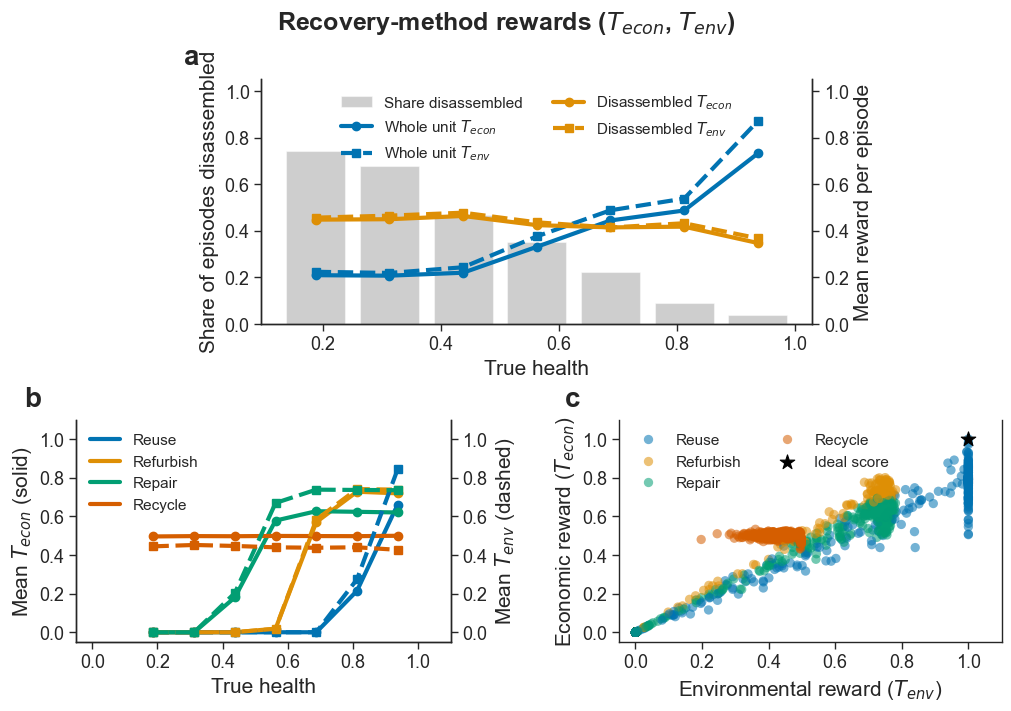

In [104]:

# Use the existing noise 0.25 experiment dataframe.
rw = df.copy()

rw["health_bin"] = pd.cut(rw["true_health"], np.linspace(0, 1, 9), include_lowest=True)
rw["health_mid"] = rw["health_bin"].apply(lambda b: b.mid if pd.notna(b) else np.nan).astype(float)


fig_r = plt.figure(figsize=(10, 7), constrained_layout=True)
gs = fig_r.add_gridspec(2, 6, height_ratios=[1.1, 1])

# a) Component rows per episode are a proxy for disassembly.
ax = fig_r.add_subplot(gs[0, 1:5])
ep = rw.groupby("episode_id").agg(
    depth=("component_name", "size"),
    econ=("econ_reward", "mean"), env=("eco_reward", "mean"),
    true_state=("true_state", "first"), laptop_name=("laptop_name", "first"),
)


ep["health"] = [json.loads(s)[str(n)] for s, n in zip(ep["true_state"], ep["laptop_name"])]
ep["disassembled"] = ep["depth"] > 1
ep["health_bin"] = pd.cut(ep["health"], np.linspace(0, 1, 9), include_lowest=True)
ep["health_mid"] = ep["health_bin"].apply(lambda b: b.mid if pd.notna(b) else np.nan).astype(float)
_dis = ep.groupby("health_mid", observed=True)["disassembled"].mean()

ax.bar(_dis.index, _dis, width=0.1, color=ce_palette["Unknown"], alpha=0.45, label="Share disassembled")
ax.set(xlabel="True health", ylabel="Share of episodes disassembled", ylim=(0, 1.05))


ax2 = ax.twinx()
for flag, lab, col in [(False, "Whole unit", _palette[0]), (True, "Disassembled", _palette[1])]:
    g = ep[ep["disassembled"] == flag].groupby("health_mid", observed=True)[["econ", "env"]].mean()
    ax2.plot(g.index, g["econ"], color=col, marker="o", markersize=marker_size, linewidth=line_width, label=rf"{lab} $T_{{econ}}$")
    ax2.plot(g.index, g["env"], color=col, marker="s", markersize=marker_size, linewidth=line_width, ls="--", label=rf"{lab} $T_{{env}}$")
ax.set_xlabel("True health", fontsize=label_fontsize)
ax.set_ylabel("Share of episodes disassembled", fontsize=label_fontsize)
ax.tick_params(labelsize=tick_fontsize)
ax2.set_ylabel("Mean reward per episode", fontsize=label_fontsize)
ax2.tick_params(labelsize=tick_fontsize)
ax2.set_ylim(0, 1.05)
_h1, _l1 = ax.get_legend_handles_labels()
_h2, _l2 = ax2.get_legend_handles_labels()
ax.legend(_h1 + _h2, _l1 + _l2, frameon=False, fontsize=legend_fontsize, ncol=2, loc="upper center")
ax.text(-0.14, 1.06, "a", transform=ax.transAxes, fontweight="bold", fontsize=panel_fontsize)

# b) Mean economic and environmental rewards by health and recovery method.
ax = fig_r.add_subplot(gs[1, :3])
ax2 = ax.twinx()
_m = rw.groupby(["ce_route", "health_mid"], observed=True)[["econ_reward", "eco_reward"]].mean().reset_index()
for m in ce_order:
    s = _m[_m["ce_route"] == m]
    ax.plot(s["health_mid"], s["econ_reward"], color=ce_palette[m], marker="o", markersize=marker_size, linewidth=line_width)
    ax2.plot(s["health_mid"], s["eco_reward"], color=ce_palette[m], marker="s", markersize=marker_size, linewidth=line_width, ls="--")
ax.set(
    xlabel="True health", 
    ylabel=r"Mean $T_{econ}$ (solid)",
    xlim=(-0.05, 1.1), ylim=(-0.05, 1.1)
)
ax.set_xlabel("True health", fontsize=label_fontsize)
ax.set_ylabel(r"Mean $T_{econ}$ (solid)", fontsize=label_fontsize)
ax2.set(
    xlabel="True health", 
    ylabel=r"Mean $T_{env}$ (dashed)",
    xlim=(-0.05, 1.1), ylim=(-0.05, 1.1)
)
ax.tick_params(labelsize=tick_fontsize)
ax2.set_ylabel(r"Mean $T_{env}$ (dashed)", fontsize=label_fontsize)
ax2.tick_params(labelsize=tick_fontsize)
ax.legend([Line2D([], [], color=ce_palette[m], linewidth=line_width) for m in ce_order], ce_order, frameon=False, fontsize=legend_fontsize, loc="upper left")
ax.text(-0.14, 1.06, "b", transform=ax.transAxes, fontweight="bold", fontsize=panel_fontsize)

# c) Economic versus environmental scores, grouped by route and product.
ax = fig_r.add_subplot(gs[1, 3:])
sns.scatterplot(
    data=rw, x="eco_reward", y="econ_reward",
    hue="ce_route", hue_order=ce_order, palette=ce_palette,
    s=scatter_size, alpha=0.55, linewidth=0, ax=ax,
)
ax.scatter([1.0], [1.0], color="black", marker="*", s=120, label="Ideal score", zorder=5)
ax.set(
    ylabel=r"Economic reward ($T_{econ}$)",
    xlabel=r"Environmental reward ($T_{env}$)",
    xlim=(-0.05, 1.1), ylim=(-0.05, 1.1),
)
ax.set_ylabel(r"Economic reward ($T_{econ}$)", fontsize=label_fontsize)
ax.set_xlabel(r"Environmental reward ($T_{env}$)", fontsize=label_fontsize)
ax.tick_params(labelsize=tick_fontsize)
ax.legend(frameon=False, fontsize=legend_fontsize, title=None, ncol=2, loc="upper left")
ax.text(-0.14, 1.06, "c", transform=ax.transAxes, fontweight="bold", fontsize=panel_fontsize)

sns.despine(fig=fig_r, right=False)
fig_r.suptitle(r"Recovery-method rewards ($T_{econ}$, $T_{env}$)", fontweight="bold", fontsize=title_fontsize)

Path("plots").mkdir(parents=True, exist_ok=True)
fig_r.savefig("plots/reward_overview.pdf", bbox_inches="tight")
fig_r.savefig("plots/reward_overview.png", dpi=300, bbox_inches="tight")
plt.show()


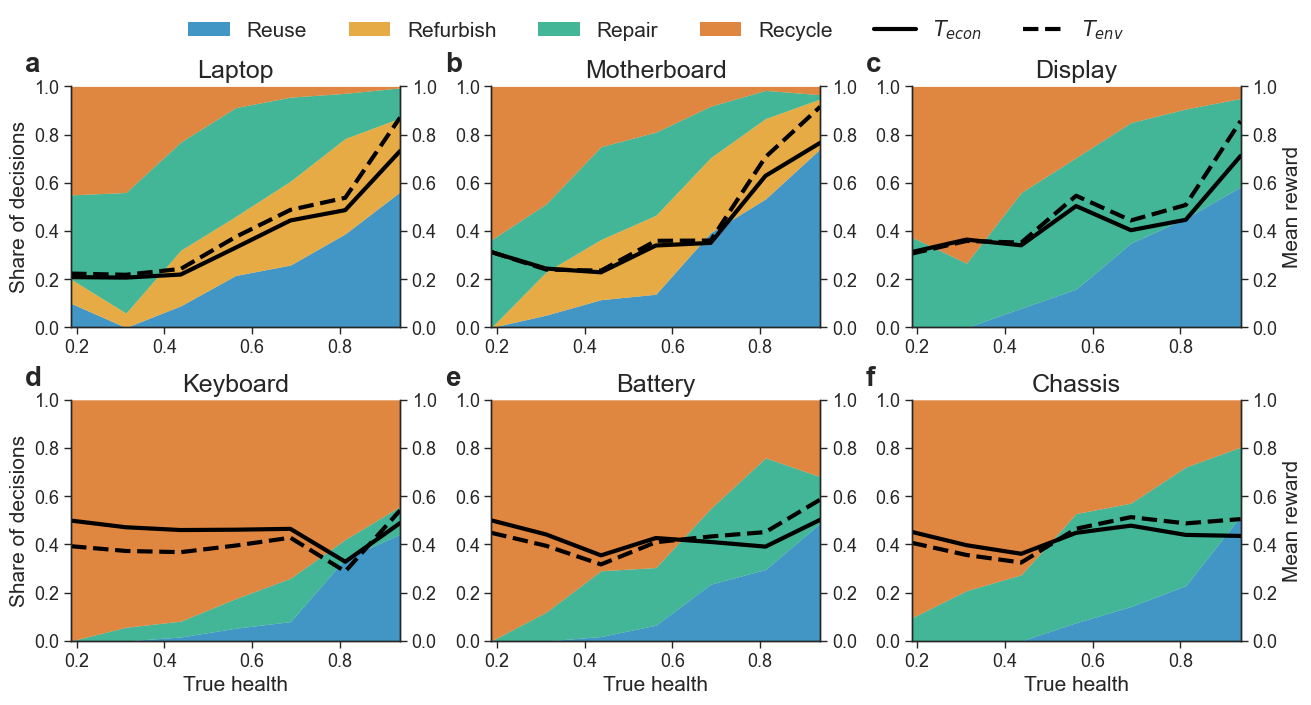

In [111]:
# ================= Figure 4: recovery pathways, all components =================
fig_p = plt.figure(figsize=(13, 7), constrained_layout=True)
gp = fig_p.add_gridspec(2, 3)
for k, prod in enumerate(rw["component_name"].unique().tolist()):
    sub = rw[rw["component_name"] == prod]
    ax = fig_p.add_subplot(gp[k // 3, k % 3])
    share = (pd.crosstab(sub["health_mid"], sub["ce_route"], normalize="index")
             .reindex(columns=ce_order, fill_value=0))
    ax.stackplot(share.index, [share[m] for m in ce_order],
                 colors=ce_palette.values(), alpha=0.75, linewidth=0, labels=ce_order)
    ax.set(xlim=(share.index.min(), share.index.max()), ylim=(0, 1), title=prod)
    ax.set_title(prod, fontsize=title_fontsize)
    ax.set_xlabel("True health" if k // 3 == 1 else "", fontsize=label_fontsize)
    ax.set_ylabel("Share of decisions" if k % 3 == 0 else "", fontsize=label_fontsize)
    ax.tick_params(labelsize=tick_fontsize)
    ax2 = ax.twinx()
    _r = sub.groupby("health_mid")[["econ_reward", "eco_reward"]].mean()
    ax2.plot(_r.index, _r["econ_reward"], color="black", linewidth=line_width, label=r"$T_{econ}$")
    ax2.plot(_r.index, _r["eco_reward"], color="black", linewidth=line_width, ls="--", label=r"$T_{env}$")
    ax2.set_ylim(0, 1.0)
    ax2.set_ylabel("Mean reward" if k % 3 == 2 else "", fontsize=label_fontsize)
    ax2.tick_params(labelsize=tick_fontsize)
    if k == 0:
        _h1, _l1 = ax.get_legend_handles_labels()
        _h2, _l2 = ax2.get_legend_handles_labels()
        fig_p.legend(_h1 + _h2, _l1 + _l2, frameon=False, fontsize=15, ncol=6,
                     loc="outside upper center")
    ax.text(-0.14, 1.06, "abcdef"[k], transform=ax.transAxes,
            fontweight="bold", fontsize=panel_fontsize)
sns.despine(fig=fig_p, right=False)

Path("plots").mkdir(parents=True, exist_ok=True)
fig_p.savefig("plots/recovery_pathways.pdf", bbox_inches="tight")
fig_p.savefig("plots/recovery_pathways.png", dpi=300, bbox_inches="tight")

plt.show()

In [ ]:
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(22, 9), sharey=True)

# --- Plot 1: Economic Reward vs. Cost ---
sns.scatterplot(
    data=df,
    x="cost",
    y="econ_reward",
    hue="ce_route",
    palette=ce_palette,
    s=60,
    alpha=0.7,
    edgecolor="black",
    linewidth=0.4,
    ax=ax1,
)
ax1.set_title("Economic Reward vs. Total Path Cost", fontsize=16, weight="bold")
ax1.set_xlabel("Total Path Cost (£)", fontsize=14)
ax1.set_ylabel("Economic Reward (T_econ)", fontsize=14)
ax1.legend(title="Triage Decision")
ax1.set_ylim(-0.05, 1.05)  # Set common y-axis limit for both plots

# --- Plot 2: Ecological Reward vs. Cost ---
sns.scatterplot(
    data=df,
    x="cost",
    y="eco_reward",
    hue="ce_route",
    palette=ce_palette,
    s=60,
    alpha=0.7,
    edgecolor="black",
    linewidth=0.4,
    ax=ax2,
)
ax2.set_title("Ecological Reward vs. Total Path Cost", fontsize=16, weight="bold")
ax2.set_xlabel("Total Path Cost (£)", fontsize=14)
# The y-axis label is shared from the first plot, so we can hide this one.
ax2.set_ylabel("")
# Remove the legend from the second plot to reduce redundancy
ax2.get_legend().remove()


# --- 4. Final Customization and Display ---
fig.suptitle("Triage Reward vs. Cost Analysis", fontsize=20, weight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])  # Adjust layout to make room for suptitle
plt.savefig('plots/econ_eco_vs_path_costs.png', bbox_inches='tight')
plt.show()

In [ ]:


fig, ax = plt.subplots(figsize=(10, 7))

sns.barplot(
    data=df,
    x="ce_route",
    y="cost",
    palette="plasma",  # Using a different color palette for variety
    ax=ax,
)

# --- 4. Add Data Labels on Top of Bars ---
# This adds the exact average cost value on top of each bar for clarity.
for p in ax.patches:
    ax.annotate(
        f"£{p.get_height():.2f}",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="center",
        fontsize=11,
        color="black",
        xytext=(0, 9),
        textcoords="offset points",
    )

# --- 5. Customize and Show the Plot ---
ax.set_title(
    "Average Path Cost per Triage Decision", fontsize=16, weight="bold", pad=20
)
ax.set_xlabel("Circular Economy Route", fontsize=12)
ax.set_ylabel("Average Cost (£)", fontsize=12)

# Increase the y-axis limit to make space for the labels on top of the bars
ax.set_ylim(0, ax.get_ylim()[1] * 1.1)

plt.tight_layout()
plt.savefig('plots/avg_path_costs.png', bbox_inches='tight')
plt.show()

In [ ]:



fig, ax = plt.subplots(figsize=(12, 8))

sns.violinplot(
    data=df,
    x="ce_route",
    y="cost",
    palette="viridis",
    inner="box",  # Adds a box plot inside the violins to show quartiles
    ax=ax,
)


ax.set_title(
    "Distribution of Path Costs for Each Triage Decision",
    fontsize=18,
    weight="bold",
    pad=20,
)
ax.set_xlabel("Circular Economy Route", fontsize=14)
ax.set_ylabel("Total Path Cost (£)", fontsize=14)
ax.tick_params(axis="x", labelsize=12)
ax.tick_params(axis="y", labelsize=12)

plt.tight_layout()
plt.savefig('plots/dist_of_path_costs.png', bbox_inches='tight')
plt.show()